# HW 2: External Data, Visualization & Modular Code

In [33]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import utils


## Part 1: Load Data
Dataset: `mining-production.csv`

Sourced from: https://github.com/kadoa-org/world-mining-monitor

Download from: https://www.kadoa.com/mining/production

Acsessed Oct 17, 2026 12:34 pm

Saved in  data/external

In [34]:
# Read data in
data = pd.read_csv("../data/raw/mining-production.csv")
data.sample(10)

,company,operation,commodity,product_form,metric,period,value,unit,qoq_pct,country,...,source_document_name,source_page,source_section,source_table,source_row,source_column,source_excerpt,reported_value,reported_unit,reported_period
5287,Barrick Gold,Tongon,gold,NaN,production,9M 2025,98.000000,koz,NaN,NaN,...,barrick-q3-2025-mine-stats.pdf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7616,Freeport-McMoRan,South America operations,molybdenum,NaN,production,9M 2024,6.803890,kt,NaN,NaN,...,freeport-q3-2025.pdf,39.0,South America,Operating Data,Molybdenum (millions of recoverable pounds) Pr...,"Nine Months Ended September 30, 2024",Production 15,15,millions of recoverable pounds,"Nine Months Ended September 30, 2024"
2652,Alro SA,NaN,aluminium,sheets,production,Q4 2025,4.744000,kt,6.7,NaN,...,ALRO-GROUP-Trading-Update-Q1-2026.pdf,1.0,Production & Sales,Production,Sheets,Q4/25,"Sheets tonnes 4,049 3,960 4,448 4,744 4,294","4,744",tonnes,Q4/25
2475,Merdeka Copper Gold,AIM,copper,cathode,production,Q4 2025,0.321000,kt,NaN,NaN,...,merdeka-copper-gold-q4-2025-activities.pdf,1.0,Highlights,NaN,NaN,NaN,AIM produced a total of 321 tonnes of LME-grad...,321,tonnes,quarter
7969,Nornickel,NaN,nickel,ore,production,FY2024,27149.000000,kt,NaN,NaN,...,h1-2026-994d867d.xlsx,NaN,ORE OUTPUT,NORILSK NICKEL GROUP ORE OUTPUT,"TOTAL ORE OUTPUT (sulfide copper-nickel ore), ...",2024,A2=TOTAL ORE OUTPUT (sulfide copper-nickel ore...,"27,149",kt,2024
9143,KGHM,Sierra Gorda S.C.M.,molybdenum,NaN,production,July 2025,0.317515,kt,NaN,NaN,...,Production-Sales_20report_KGHM__20July_2026.pdf,5.0,Results of Sierra Gorda S.C.M. in July 2026 - ...,Production and sales of Sierra Gorda S.C.M. (o...,Molybdenum (mn lb),July 2025,Molybdenum (mn lb) | 0.7,0.7,mn lb,July 2025
898,Hudbay Minerals,NaN,gold,concentrate and doré,production,Q1 2026,61.700000,koz,-26.8,NaN,...,MDA526.pdf,NaN,KEY PRODUCTION RESULTS,KEY PRODUCTION RESULTS,Gold,"Mar. 31, 2026","Gold oz 61,700","61,700",oz,"Mar. 31, 2026"
5876,Glencore,Cerrejón,coal,thermal coal,production,H1 2025,8900.000000,kt,NaN,NaN,...,GLEN-2026-Half-Year-Report.pdf,21.0,INDUSTRIAL ACTIVITIES,Coal assets1,Cerrejón thermal coal,H1 2025,Cerrejón thermal coal mt 8.3 8.9 (7),8.9,mt,H1 2025
8441,BHP,Copper South Australia,copper,NaN,production,H2 2023,153.700000,kt,NaN,NaN,...,bhp-h1-fy2025.pdf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7790,Newmont,Akyem,gold,NaN,production,H1 2024,116.000000,koz,NaN,Ghana,...,newmont-q2-2024-10-q-__final.pdf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
#inspect shape, columns, dtypes, and missingness
print(f"Shape: {data.shape}\n")
print(f"Columns: {data.columns}\n")

Shape: (9410, 22)

Columns: Index(['company', 'operation', 'commodity', 'product_form', 'metric', 'period',
       'value', 'unit', 'qoq_pct', 'country', 'basis', 'source_url',
       'source_document_name', 'source_page', 'source_section', 'source_table',
       'source_row', 'source_column', 'source_excerpt', 'reported_value',
       'reported_unit', 'reported_period'],
      dtype='str')



In [36]:
# Inspect data types
print(f"Dtypes: \n{data.dtypes}\n")

Dtypes: 
company                     str
operation                   str
commodity                   str
product_form                str
metric                      str
period                      str
value                   float64
unit                        str
qoq_pct                 float64
country                     str
basis                       str
source_url                  str
source_document_name        str
source_page             float64
source_section              str
source_table                str
source_row                  str
source_column               str
source_excerpt              str
reported_value              str
reported_unit               str
reported_period             str
dtype: object



In [37]:
# List of columns with the amount missing, sorted by value
print(f"Missingness: \n{data.isna().sum().sort_values()}\n")

Missingness: 
company                    0
commodity                  0
period                     0
metric                     0
basis                      0
source_url               302
source_document_name     302
value                    357
unit                     357
operation               2570
source_excerpt          3835
reported_value          3835
reported_unit           3835
reported_period         3835
source_section          4028
source_page             4099
source_row              4204
source_column           4261
source_table            4399
product_form            5181
qoq_pct                 5207
country                 6865
dtype: int64



In [38]:
# Proportion missing
print(f"Missingness Proportion out of {len(data)} rows: \n{round((data.isna().sum()/len(data)*100).sort_values(), 3)}%\n")

Missingness Proportion out of 9410 rows: 
company                  0.000
commodity                0.000
period                   0.000
metric                   0.000
basis                    0.000
source_url               3.209
source_document_name     3.209
value                    3.794
unit                     3.794
operation               27.311
source_excerpt          40.755
reported_value          40.755
reported_unit           40.755
reported_period         40.755
source_section          42.806
source_page             43.560
source_row              44.676
source_column           45.282
source_table            46.748
product_form            55.058
qoq_pct                 55.335
country                 72.954
dtype: float64%



### Part 3 — Exploratory analysis

Answer at least two data questions.


Use appropriate summaries such as:
* counts;
* means/medians;
* grouped summaries;
* distributions;
* associations.

Explain the substantive meaning of the results.

#### Questions:
1. How much of each commodity is produced in total each quarter? (Grouped Summary)
2. How many companies mine each commodity? What is the distribution of number of commodities mined per company?

### Question 1: How much of each commodity is produced in total each quarter?

Requires that the units and times are homogenized.
Returns 595 totals, so a peek at the max (most mined commodity the 7 year period) is more interesting.

In [39]:
data["unit"].value_counts() # Convert these all to kg

unit
kt      5962
koz     3055
kcts      36
Name: count, dtype: int64

In [40]:
data_homogenized_units = utils.apply_extraction_units(data, "kg_mined", "unit", "value")

data_homogenized_units[["commodity", "kg_mined", "unit", "value"]].sample(5)

,commodity,kg_mined,unit,value
1398,thermal coal,3.000000e+09,kt,3000.000
1921,aluminium,1.190000e+08,kt,119.000
2397,copper,1.515000e+08,kt,151.500
481,coal,7.000000e+09,kt,7000.000
4052,copper,1.143300e+07,kt,11.433


In [66]:
data["period"].value_counts() # 82 different time periods over 7 years x 4 quarters


period
Q1 2026                          937
Q1 2025                          811
Q2 2026                          790
Q4 2025                          695
Q2 2025                          685
                                ... 
Annual Average                     3
9M FY2026                          3
9M FY2024 (Oct 2023-Jun 2024)      2
HY2026 (Jul-Dec 2025)              2
H1 FY2025                          2
Name: count, Length: 82, dtype: int64

In [68]:
time_and_kg_homogenized = utils.homogenize_time_periods_and_split_values(data_homogenized_units, "period", value_cols=["value"])

print(f"Data Length before: {len(data)}\nData Length after: {len(time_and_kg_homogenized)}")
print(f"\n\nNumber of raw period values: {len(time_and_kg_homogenized["period"].unique())} (after dropping aggregates)\n"
      f"Number of homogenized period values: {len(time_and_kg_homogenized["quarter"].unique())}")

Data Length before: 9410
Data Length after: 14788


Number of raw period values: 78 (after dropping aggregates)
Number of homogenized period values: 28


In [43]:
time_and_kg_homogenized["quarter"].value_counts() # now we have 28 different values

quarter
Q1 2025    2221
Q2 2025    2071
Q1 2026    1748
Q2 2026    1550
Q3 2025    1356
Q4 2025    1312
Q1 2024     915
Q2 2024     834
Q3 2024     623
Q4 2024     581
Q2 2023     224
Q1 2023     220
Q3 2023     148
Q4 2023     123
Q3 2026     104
Q4 2022      76
Q3 2022      70
Q2 2022      65
Q4 2021      62
Q1 2022      60
Q4 2026      59
Q3 2021      57
Q2 2021      57
Q1 2021      52
Q4 2020      50
Q3 2020      50
Q2 2020      50
Q1 2020      50
Name: count, dtype: int64

In [44]:
# keep only necessary columns
processed_data_question_1 = time_and_kg_homogenized[["commodity", "kg_mined", "quarter"]]

# create grouped summary
processed_data_question_1.groupby(["commodity", "quarter"])["kg_mined"].sum()

commodity  quarter
3e pgm     Q1 2025    0.000000e+00
alumina    Q1 2023    1.894600e+10
           Q1 2024    4.709520e+10
           Q1 2025    7.868840e+10
           Q1 2026    3.837339e+10
                          ...     
zircon     Q1 2025    8.600000e+07
           Q1 2026    2.400000e+07
           Q2 2024    3.200000e+07
           Q2 2025    8.900000e+07
           Q2 2026    1.200000e+07
Name: kg_mined, Length: 595, dtype: float64

In [45]:
# Check the total amount mined per commodity in decreasing order for fun
commodity_totals = (
    processed_data_question_1.groupby("commodity")["kg_mined"].sum()
    .sort_values(ascending=False)
)

commodity_totals

commodity
iron ore                       2.055913e+13
coal                           3.726021e+12
bauxite                        1.685218e+12
alumina                        6.555345e+11
copper                         6.139946e+11
aluminium                      4.352164e+11
nickel                         4.246465e+11
thermal coal                   3.247000e+11
zinc                           2.471545e+11
manganese                      1.916740e+11
phosphate                      1.061875e+11
chromite                       3.006500e+10
lead                           2.734794e+10
mineral_sands                  2.013700e+10
mined metal                    2.002800e+10
refined metal                  1.693800e+10
semi-soft coking coal          1.210000e+10
pig iron                       8.798000e+09
chrome                         8.127000e+09
titanium_dioxide               6.353000e+09
saleable metal                 3.872000e+09
cobalt                         3.039448e+09
molybdenum            

### Question 2: How many companies mine each commodity? What is the distribution of number of commodities mined per company?

In [46]:
q2_data = time_and_kg_homogenized[["commodity", "kg_mined", "company"]]

# Check missingness
q2_data.isna().sum()

commodity      0
kg_mined     579
company        0
dtype: int64

In [47]:
#fill zeroes for missing values
q2_data_filledna = q2_data.fillna(0)
q2_data_filledna.isna().sum()


commodity    0
kg_mined     0
company      0
dtype: int64

In [48]:
# a: How many companies mine each commodity?
# https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.nunique.html
q2_summary_a = q2_data.groupby("commodity")["company"].nunique().sort_values(ascending=False)
q2_summary_a

commodity
copper                         44
gold                           41
silver                         31
zinc                           25
lead                           18
nickel                         18
molybdenum                     16
aluminium                      15
cobalt                         12
alumina                         9
iron ore                        9
pgm                             9
bauxite                         5
coal                            5
manganese                       4
chrome                          3
lithium                         3
diamonds                        2
nickel pig iron                 2
phosphate                       2
tungsten                        2
chromite                        2
uranium                         2
ammonium bisulphite             1
3e pgm                          1
ammonium sulphate               1
magnetite                       1
magnesium sulphate              1
lithium hydroxide               1
liqu

In [49]:
# b: How many commodities are mined on average per company?
q2_summary_b = q2_data.groupby("company")["commodity"].nunique()
print(f"The average number of commodites mined by a company is {int(round(q2_summary_b.mean(), 0))}")

The average number of commodites mined by a company is 5


### Part 4 — Visualization

Create at least three plots:

1. one distribution plot;
2. one comparison across groups;
3. one relationship plot.

The figures must include:
* meaningful title;
* axis labels;
* units where appropriate;
* readable legend;
* short caption explaining the conclusion.

### 1. Distribution Plot: Histogram

commodity_name        str
Kg_mined          float64
dtype: object


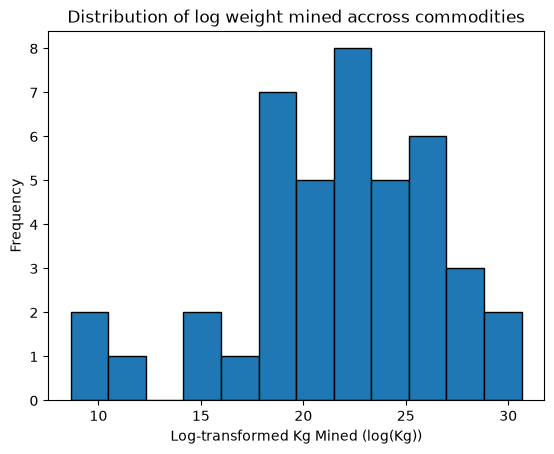

In [50]:
commodity_totals_df = pd.DataFrame({"commodity_name" : commodity_totals.index, "Kg_mined" : commodity_totals.values})
print(commodity_totals_df.dtypes)

# Since kg_mined is numeric and has a very wide range, take a log transform -> not a safe function if cells
# are run out of order
commodity_totals_df = utils.log_transform(commodity_totals_df, "Kg_mined", "Kg_mined_log")

plt.hist(x = commodity_totals_df["Kg_mined_log"],
         bins = 12,
         edgecolor = "black")
plt.title("Distribution of log weight mined accross commodities")
plt.xlabel("Log-transformed Kg Mined (log(Kg))")
plt.ylabel("Frequency")
plt.show()

### 2. Comparison Plot: Mean amount of Gold mined across quarters for all years

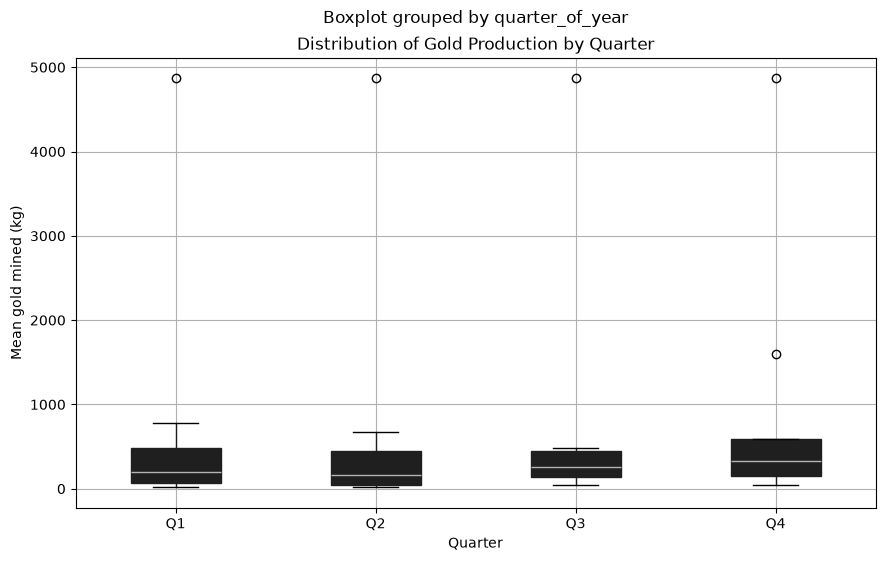

In [51]:
gold_df = time_and_kg_homogenized[time_and_kg_homogenized["commodity"] == "gold"].dropna().copy()

# add a column to group by quarter
gold_df["quarter_of_year"] = gold_df["quarter"].str.extract(r"(Q[1-4])")

gold_df.boxplot(column='kg_mined', by='quarter_of_year', figsize=(10, 6),
                patch_artist = True)

plt.title("Distribution of Gold Production by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Mean gold mined (kg)")
plt.show()


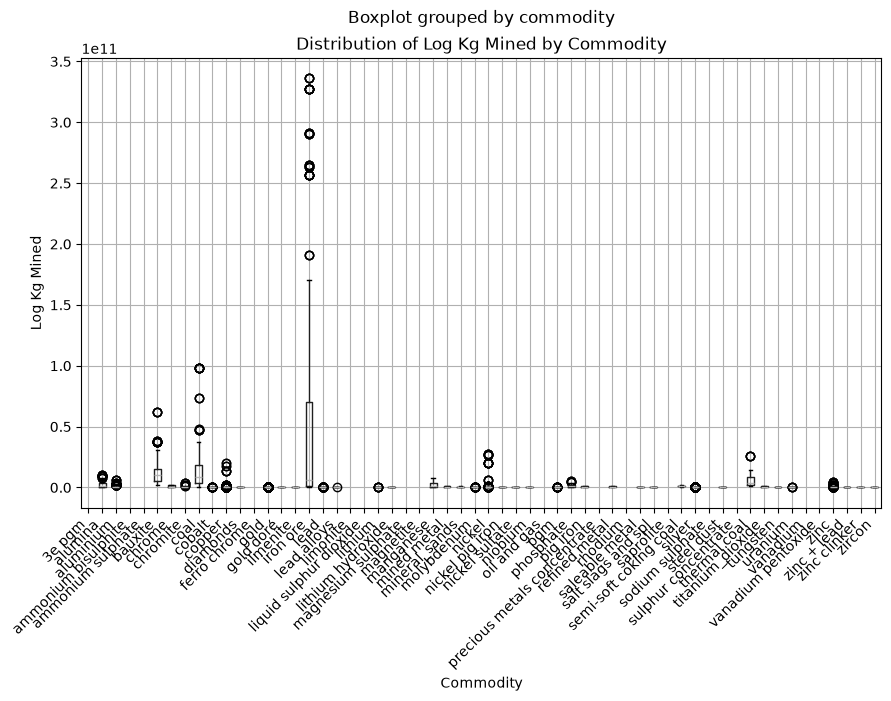

In [78]:
all_amounts_mined = time_and_kg_homogenized[["commodity", "kg_mined", "quarter", "year"]].copy()

all_amounts_mined.boxplot(column='kg_mined', by='commodity', figsize=(10, 6))

plt.title('Distribution of Log Kg Mined by Commodity')
plt.xlabel('Commodity')
plt.ylabel('Log Kg Mined')
plt.xticks(rotation=45, ha='right')
plt.show()


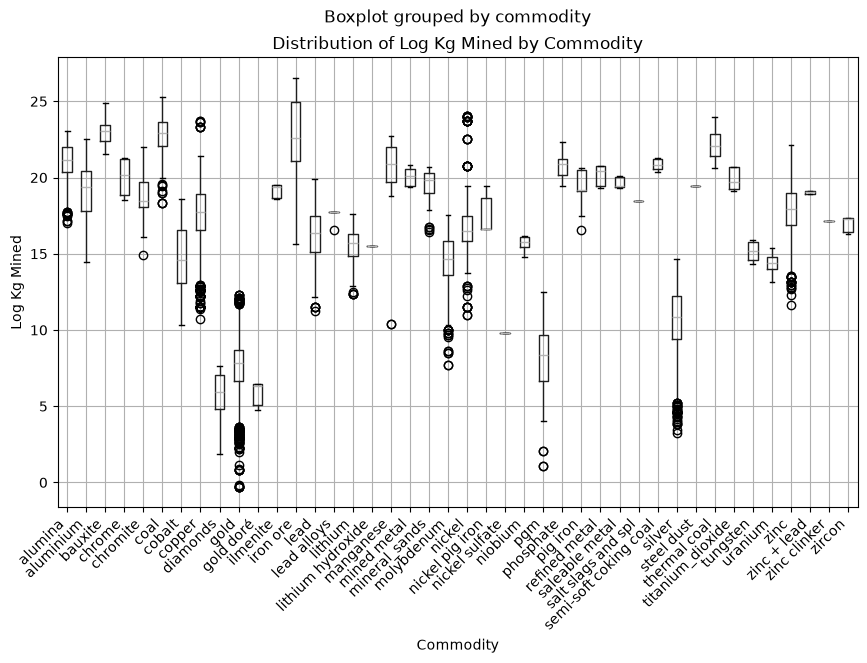

In [86]:
log_amounts_mined = utils.log_transform(all_amounts_mined, "kg_mined", "log_kg_mined")

log_amounts_mined.boxplot(column='log_kg_mined', by='commodity', figsize=(10, 6))

plt.title('Distribution of Log Kg Mined by Commodity')
plt.xlabel('Commodity')
plt.ylabel('Log Kg Mined')
plt.xticks(rotation=45, ha='right')
plt.show()

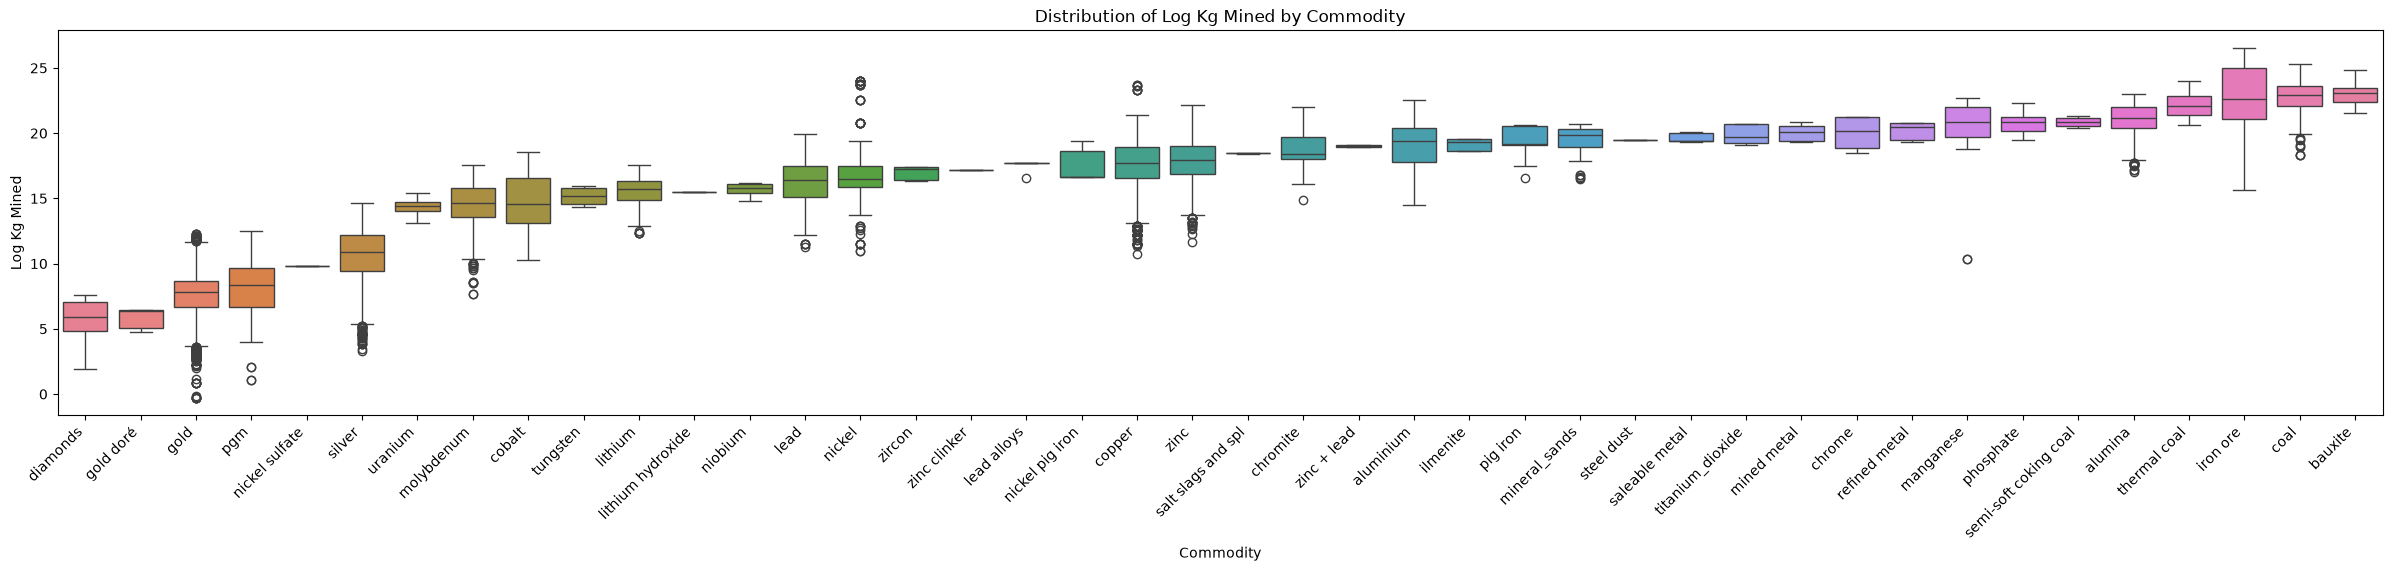

In [90]:
log_amounts_mined = utils.log_transform(all_amounts_mined, "kg_mined", "log_kg_mined")

commodity_order = ( # order commodities by mean so a relationship is easier to see
    log_amounts_mined.groupby("commodity")["log_kg_mined"]
    .mean()
    .sort_values()
    .index
)
commodity_palette = dict( # make it pretty!
    zip(commodity_order, sns.color_palette("husl", n_colors=len(commodity_order)))
)
fig, ax = plt.subplots(figsize=(30, 5))

ax = sns.boxplot(
    data=log_amounts_mined,
    x="commodity",
    y="log_kg_mined",
    order=commodity_order,
    hue="commodity",
    hue_order=commodity_order,
    palette=commodity_palette,
    dodge=False,
)
if ax.get_legend() is not None:
    ax.get_legend().remove()

plt.title("Distribution of Log Kg Mined by Commodity")
plt.xlabel("Commodity")
plt.ylabel("Log Kg Mined")
plt.xticks(rotation=45, ha="right")
plt.show()

In [ ]:
top_5_commodities = list(time_and_kg_homogenized["commodity"].value_counts().head().index)
top_5_commodities

['copper', 'gold', 'silver', 'zinc', 'lead']

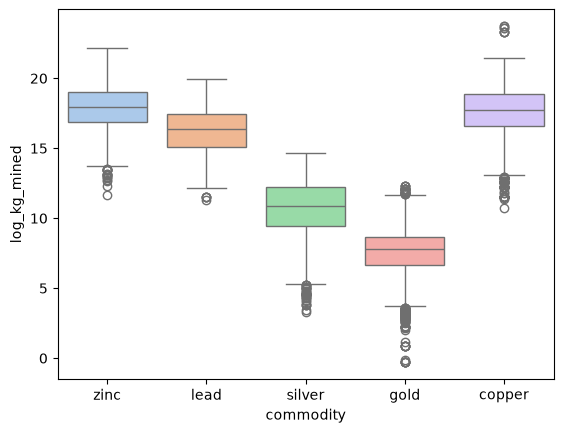

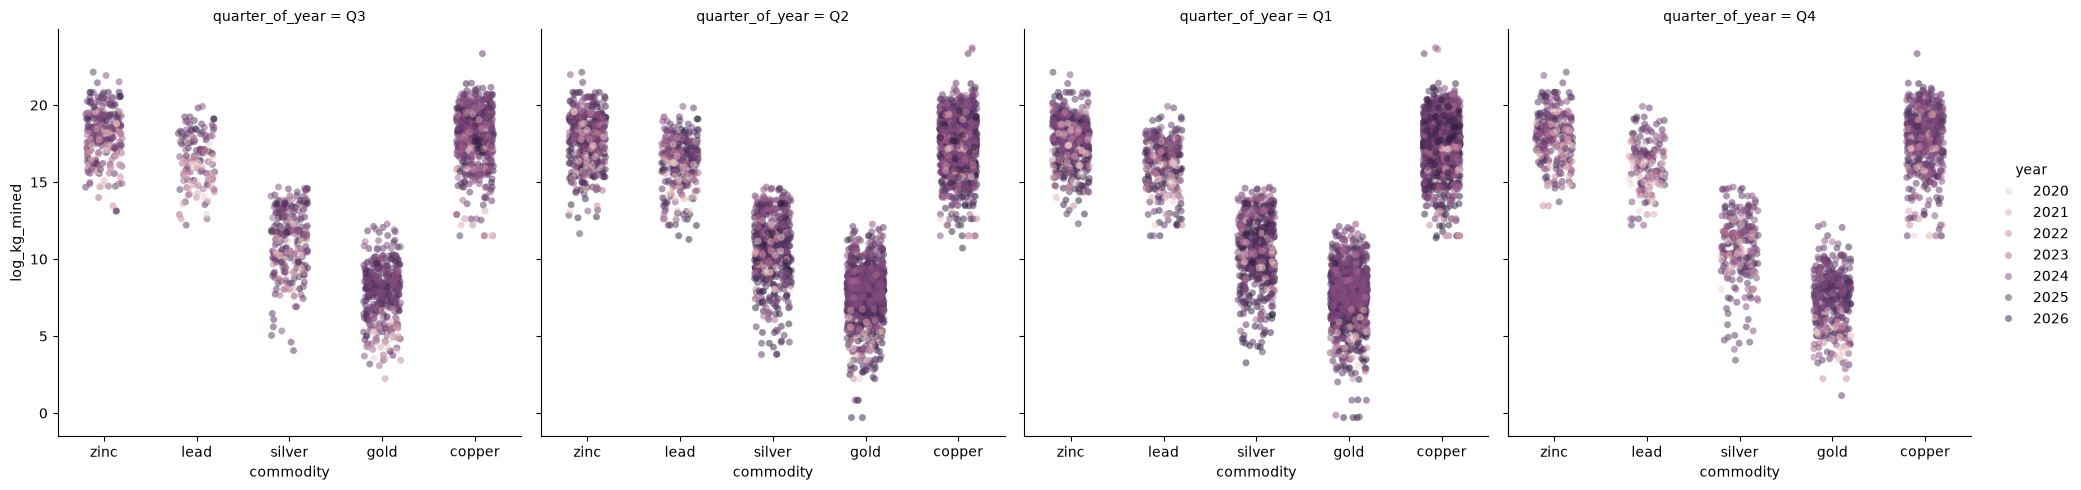

In [84]:
# Top 5 commodities (by occurance) Using Seaborn
top_5 = log_amounts_mined[log_amounts_mined["commodity"].isin(top_5_commodities)]
top_5["quarter_of_year"] = top_5["quarter"].str.extract(r"(Q[1-4])")


sns.boxplot(
    data= top_5,
    y="log_kg_mined",
    x="commodity",
    hue = "commodity",
    palette="pastel"
)
sns.catplot(
    data= top_5,
    y="log_kg_mined",
    x="commodity",
    hue = "year",
    col = "quarter_of_year",
    alpha = 0.5,
    jitter=0.2
    
)



### 3. Relationship Plot: Amount of the top 3 commodities (by appearance in data) are mined over time

/tmp/ipykernel_6482/808061153.py:7: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=top_10, x='quarter', y='log_kg_mined', hue='commodity',ci=None)


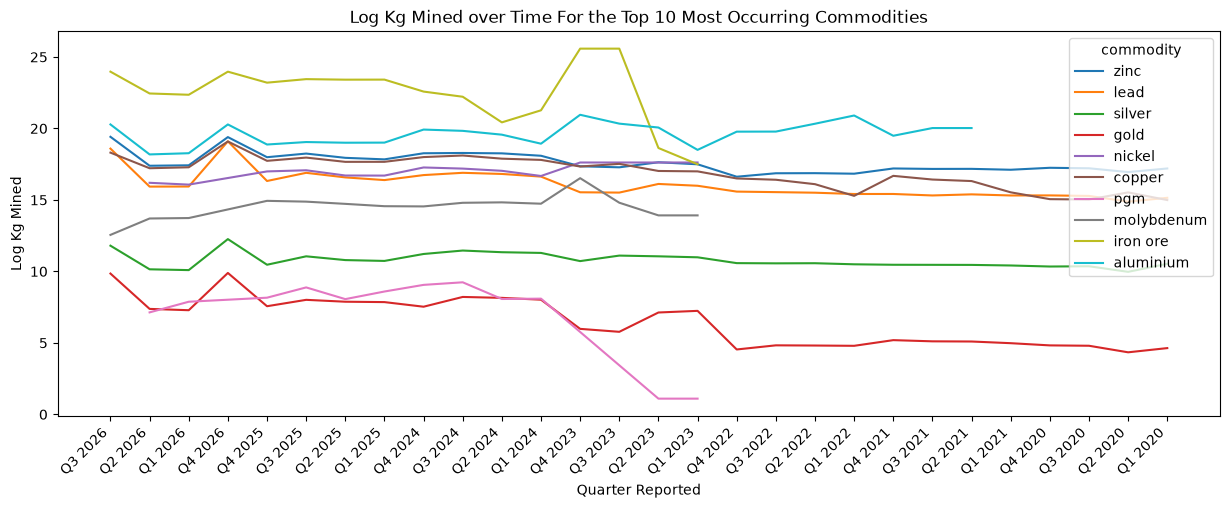

In [106]:
top_10_commodities = list(time_and_kg_homogenized["commodity"].value_counts().head(10).index)

top_10 = log_amounts_mined[log_amounts_mined["commodity"].isin(top_10_commodities)]

fig, ax = plt.subplots(figsize=(15, 5))

sns.lineplot(data=top_10, x='quarter', y='log_kg_mined', hue='commodity',ci=None)
plt.xlabel('Quarter Reported')
plt.ylabel('Log Kg Mined')
plt.title('Log Kg Mined over Time For the Top 10 Most Occurring Commodities')
plt.xticks(rotation=45, ha='right')
plt.show()